<a href="https://colab.research.google.com/github/samhithraj-186/ML_LAB_2026-2027/blob/main/Heart_Disease_Prediction_ML_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install ucimlrepo

In [2]:
from ucimlrepo import fetch_ucirepo

# Import Heart Disease Dataset
heart_disease = fetch_ucirepo(id=45)

# Store features and target
X = heart_disease.data.features
y = heart_disease.data.targets

print("Dataset imported successfully!")

Dataset imported successfully!


In [3]:
print(X.head())

print("Dataset shape:", X.shape)

print(y.head())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   63    1   1       145   233    1        2      150      0      2.3      3   
1   67    1   4       160   286    0        2      108      1      1.5      2   
2   67    1   4       120   229    0        2      129      1      2.6      2   
3   37    1   3       130   250    0        0      187      0      3.5      3   
4   41    0   2       130   204    0        2      172      0      1.4      1   

    ca  thal  
0  0.0   6.0  
1  3.0   3.0  
2  2.0   7.0  
3  0.0   3.0  
4  0.0   3.0  
Dataset shape: (303, 13)
   num
0    0
1    2
2    1
3    0
4    0


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import accuracy_score, classification_report

In [5]:
# Convert target into binary classification

y = y.iloc[:, 0]
y = (y > 0).astype(int)

print(y.value_counts())

num
0    164
1    139
Name: count, dtype: int64


In [6]:
numerical_columns = [
    'age', 'trestbps', 'chol',
    'thalach', 'oldpeak'
]

categorical_columns = [
    'sex', 'cp', 'fbs', 'restecg',
    'exang', 'slope', 'ca', 'thal'
]

In [7]:
# Numerical data preparation

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical data preparation

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both transformations

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numerical_columns),
    ('cat', categorical_transformer, categorical_columns)
])

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("Data preparation completed!")

Training samples: 242
Testing samples: 61
Data preparation completed!


In [9]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model

dt_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', DecisionTreeClassifier(random_state=42))
])

# Train the model

dt_model.fit(X_train, y_train)

# Make predictions

dt_predictions = dt_model.predict(X_test)

# Calculate accuracy

print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_predictions) * 100, "%")

print(classification_report(y_test, dt_predictions))

Decision Tree Accuracy: 73.77049180327869 %
              precision    recall  f1-score   support

           0       0.81      0.67      0.73        33
           1       0.68      0.82      0.74        28

    accuracy                           0.74        61
   macro avg       0.75      0.74      0.74        61
weighted avg       0.75      0.74      0.74        61



In [10]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model

knn_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', KNeighborsClassifier(n_neighbors=5))
])

# Train the model

knn_model.fit(X_train, y_train)

# Make predictions

knn_predictions = knn_model.predict(X_test)

# Calculate accuracy

print("KNN Accuracy:",
      accuracy_score(y_test, knn_predictions) * 100, "%")

print(classification_report(y_test, knn_predictions))

KNN Accuracy: 88.52459016393442 %
              precision    recall  f1-score   support

           0       0.91      0.88      0.89        33
           1       0.86      0.89      0.88        28

    accuracy                           0.89        61
   macro avg       0.88      0.89      0.88        61
weighted avg       0.89      0.89      0.89        61



In [11]:
from sklearn.linear_model import LogisticRegression

# Create Logistic Regression model

lr_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', LogisticRegression(max_iter=1000))
])

# Train the model

lr_model.fit(X_train, y_train)

# Make predictions

lr_predictions = lr_model.predict(X_test)

# Calculate accuracy

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, lr_predictions) * 100, "%")

print(classification_report(y_test, lr_predictions))

Logistic Regression Accuracy: 88.52459016393442 %
              precision    recall  f1-score   support

           0       0.93      0.85      0.89        33
           1       0.84      0.93      0.88        28

    accuracy                           0.89        61
   macro avg       0.89      0.89      0.89        61
weighted avg       0.89      0.89      0.89        61



In [12]:
from sklearn.svm import SVC

# Create SVM model

svm_model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('model', SVC(kernel='linear'))
])

# Train the model

svm_model.fit(X_train, y_train)

# Make predictions

svm_predictions = svm_model.predict(X_test)

# Calculate accuracy

print("SVM Accuracy:",
      accuracy_score(y_test, svm_predictions) * 100, "%")

print(classification_report(y_test, svm_predictions))

SVM Accuracy: 85.24590163934425 %
              precision    recall  f1-score   support

           0       0.93      0.79      0.85        33
           1       0.79      0.93      0.85        28

    accuracy                           0.85        61
   macro avg       0.86      0.86      0.85        61
weighted avg       0.86      0.85      0.85        61



In [13]:
results = pd.DataFrame({
    'Algorithm': [
        'Decision Tree',
        'KNN',
        'Logistic Regression',
        'SVM'
    ],

    'Accuracy (%)': [
        accuracy_score(y_test, dt_predictions) * 100,
        accuracy_score(y_test, knn_predictions) * 100,
        accuracy_score(y_test, lr_predictions) * 100,
        accuracy_score(y_test, svm_predictions) * 100
    ]
})

print(results.to_string(index=False))

          Algorithm  Accuracy (%)
      Decision Tree     73.770492
                KNN     88.524590
Logistic Regression     88.524590
                SVM     85.245902


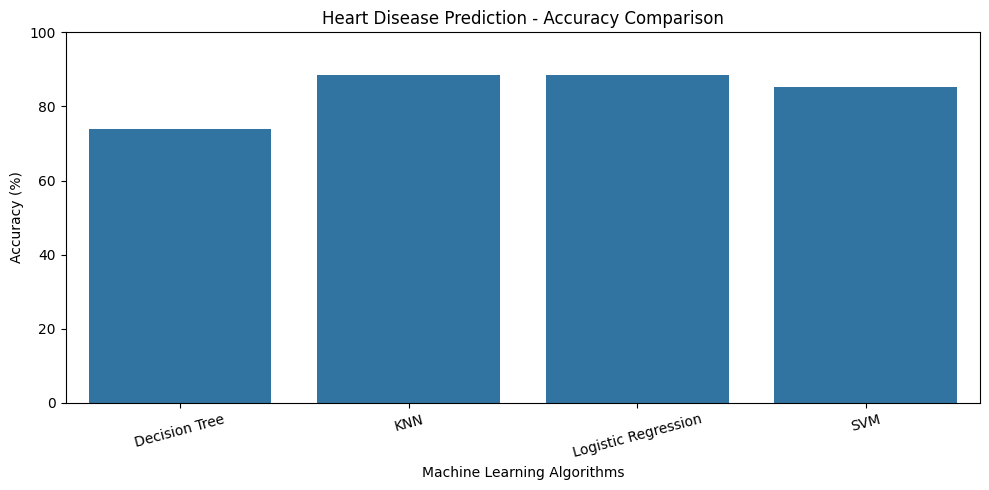

In [14]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results,
    x='Algorithm',
    y='Accuracy (%)'
)

plt.title('Heart Disease Prediction - Accuracy Comparison')

plt.xlabel('Machine Learning Algorithms')
plt.ylabel('Accuracy (%)')

plt.xticks(rotation=15)

plt.ylim(0, 100)

plt.tight_layout()
plt.show()

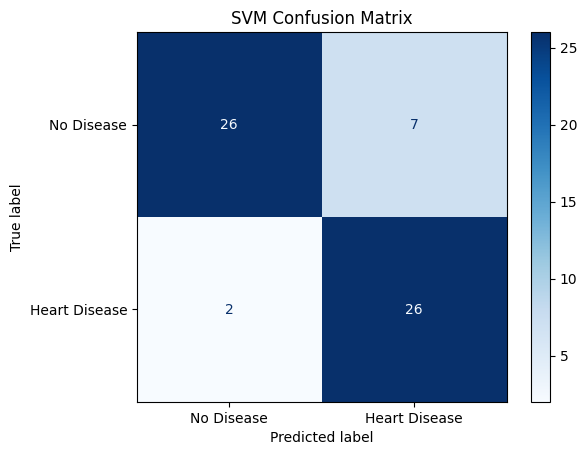

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, svm_predictions)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Disease', 'Heart Disease']
)

display.plot(cmap='Blues')

plt.title('SVM Confusion Matrix')
plt.show()